In [2]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

df = pd.read_csv('KO_weekly_return_volatility.csv')
daily_data = pd.read_csv('KO_weekly_return_detailed.csv')

train = df[df['Year'].isin([2021, 2022, 2023])].reset_index(drop=True)
test = df[df['Year'].isin([2024, 2025])].reset_index(drop=True)
daily_test = daily_data[daily_data['Year'].isin([2024, 2025])].reset_index(drop=True)

X_train = train[['mean_return', 'volatility']].values
Y_train = train['decision'].values
X_test = test[['mean_return', 'volatility']].values
Y_test = test['decision'].values

print(X_train.shape)

# train decision tree (entropy) - use same settings as decision tree assignment
dt = DecisionTreeClassifier(criterion='entropy', random_state=42)
dt.fit(X_train, Y_train)
dt_preds = dt.predict(X_test)

# train random forest with best N and d found in random forest assignment
# re-run grid to find best N and d
N_values = list(range(1, 11))
d_values = list(range(1, 6))
best_N, best_d, best_error = 1, 1, 100
for d in d_values:
    for N in N_values:
        rf = RandomForestClassifier(n_estimators=N, max_depth=d, criterion='entropy', random_state=42)
        rf.fit(X_train, Y_train)
        error = round((1 - rf.score(X_train, Y_train)) * 100, 2)
        if error < best_error:
            best_error = error
            best_N, best_d = N, d

print(f'Using Random Forest: best N={best_N}, d={best_d}')
rf_best = RandomForestClassifier(n_estimators=best_N, max_depth=best_d, criterion='entropy', random_state=42)
rf_best.fit(X_train, Y_train)
rf_preds = rf_best.predict(X_test)

# convert to binary: YES=1, NO=0
def to_binary(labels):
    return np.array([1 if l == 'YES' else 0 for l in labels])

true_traj = to_binary(Y_test)
bh_traj = np.ones(len(Y_test), dtype=int)   # buy and hold = always invested = 1
dt_traj = to_binary(dt_preds)
rf_traj = to_binary(rf_preds)

def hamming(s1, s2):
    return int(np.sum(s1 != s2))



(156, 2)
Using Random Forest: best N=10, d=5


## Q1 : Plot decision trajectories for all 4 strategies with Hamming distances in legend

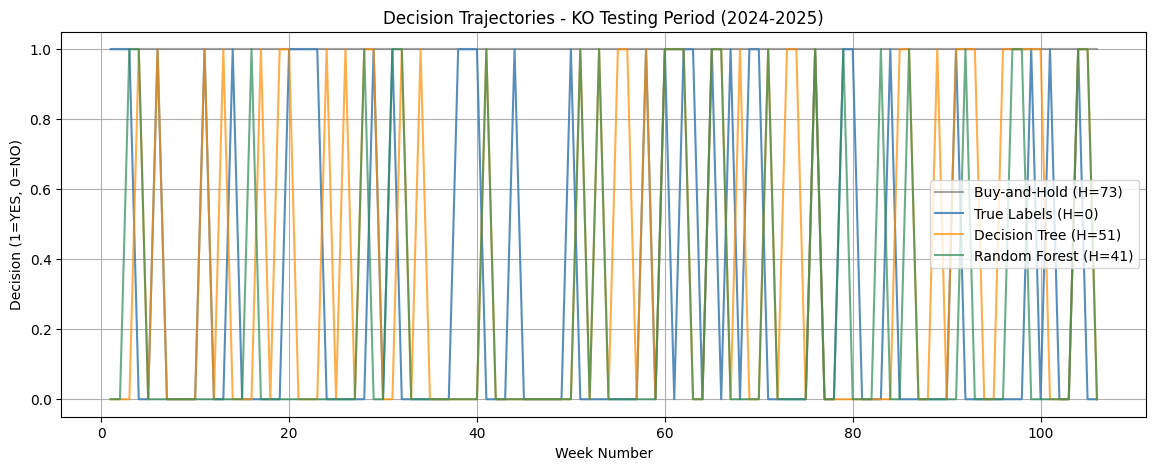

In [3]:
# Q1: plot decision trajectories with hamming distances in legend
weeks = np.arange(1, len(Y_test) + 1)

plt.figure(figsize=(14, 5))
plt.plot(weeks, bh_traj, color='grey',      label=f'Buy-and-Hold (H={hamming(bh_traj, true_traj)})',  alpha=0.7)
plt.plot(weeks, true_traj, color='steelblue', label=f'True Labels (H=0)',                               alpha=0.9)
plt.plot(weeks, dt_traj,  color='darkorange', label=f'Decision Tree (H={hamming(dt_traj, true_traj)})', alpha=0.7)
plt.plot(weeks, rf_traj,  color='seagreen',   label=f'Random Forest (H={hamming(rf_traj, true_traj)})', alpha=0.7)
plt.xlabel('Week Number')
plt.ylabel('Decision (1=YES, 0=NO)')
plt.title('Decision Trajectories - KO Testing Period (2024-2025)')
plt.legend()
plt.grid(True)
plt.savefig('decision_trajectories.png')
plt.show()

## Q2 : 4x4 Hamming distance matrix and relation to confusion matrices


In [4]:
# Q2: 4x4 Hamming distance matrix
strategies = {'Buy-and-Hold': bh_traj, 'True Labels': true_traj,
              'Decision Tree': dt_traj, 'Random Forest': rf_traj}
names = list(strategies.keys())
trajs = list(strategies.values())

print('\n4x4 Hamming Distance Matrix:')
header = f'{"":15s}' + ''.join([f'{n:15s}' for n in names])
print(header)
for i, n1 in enumerate(names):
    row = f'{n1:15s}'
    for j, n2 in enumerate(names):
        row += f'{hamming(trajs[i], trajs[j]):15d}'
    print(row)


4x4 Hamming Distance Matrix:
               Buy-and-Hold   True Labels    Decision Tree  Random Forest  
Buy-and-Hold                 0             73             64             82
True Labels                 73              0             51             41
Decision Tree               64             51              0             28
Random Forest               82             41             28              0


# show how hamming distances relate to confusion matrices

In [5]:
# show how hamming distances relate to confusion matrices
print('\nHamming distance between two strategies = number of weeks they disagree')
print('This equals FP + FN from the confusion matrix between those two strategies')
for name, traj in [('Decision Tree', dt_traj), ('Random Forest', rf_traj)]:
    cm = confusion_matrix(true_traj, traj)
    fp_fn = cm[0][1] + cm[1][0]
    h = hamming(true_traj, traj)
    print(f'{name}: H(true, pred)={h}, FP+FN from confusion matrix={fp_fn}')


Hamming distance between two strategies = number of weeks they disagree
This equals FP + FN from the confusion matrix between those two strategies
Decision Tree: H(true, pred)=51, FP+FN from confusion matrix=51
Random Forest: H(true, pred)=41, FP+FN from confusion matrix=41
